# Diabetes Project

Your task today is to **analyse** the Kaggle "Pima Indians Diabetes Database" and to **predict** whether a patient has diabetes or not, with the logistic regression you learned this week.

The task below follows the steps of a machine learning project: today you make a single pass through them, without the tuning loop you will learn in week 3.

![Today's single pass through the workflow: steps 1 to 4 (goal and metric, get the data, train-test split, explore and clean), then steps 5 to 8, where you build a random baseline, a rule-based baseline, a logistic regression and optional versions of it, and step 9, where every model is scored on the training and the test set](assets/diabetes_project_workflow.png)

# Data Description

## Context
This dataset is originally from the National Institute of Diabetes and Digestive and Kidney Diseases. The objective of the dataset is to diagnostically predict whether or not a patient has diabetes, based on certain diagnostic measurements included in the dataset. Several constraints were placed on the selection of these instances from a larger database. In particular, all patients here are females at least 21 years old of Pima Indian heritage.

## Acknowledgements
Smith, J.W., Everhart, J.E., Dickson, W.C., Knowler, W.C., & Johannes, R.S. (1988). Using the ADAP learning algorithm to forecast the onset of diabetes mellitus. In Proceedings of the Symposium on Computer Applications and Medical Care (pp. 261--265). IEEE Computer Society Press.

## About this dataset
The datasets consist of several medical predictor (independent) variables and one target (dependent) variable, Outcome. Independent variables include the number of pregnancies the patient has had, their BMI, insulin level, age, and so on. For the outcome class value 1 is interpreted as "tested positive for diabetes".

|Column Name| Description|
|:------------|:------------|
|Pregnancies|Number of times pregnant|
|Glucose|Plasma glucose concentration a 2 hours in an oral glucose tolerance test|
|BloodPressure|Diastolic blood pressure (mm Hg)|
|SkinThickness|Triceps skin fold thickness (mm)|
|Insulin|2-Hour serum insulin (mu U/ml)|
|BMI|Body mass index (weight in kg/(height in m)^2)|
|DiabetesPedigreeFunction| Diabetes pedigree function|
|Age| Age (years)|
|Outcome|Class variable (0 or 1) |

## Task

1. **Set your goal.**
    - **Choose your metric.** Before you model anything, decide which evaluation metric matters most for this problem, and explain why. Think about which mistake is worse for a patient: a missed diabetes case or a false alarm.
    - **Formulate a research question and three hypotheses**. The research question states what you want to find out about the patients. Each hypothesis is a statement about the data that the data can support or contradict, written in the form *"if ..., then ..."* or *"the more ..., the more ..."*. Base them on the data description above and on what you know about diabetes, not on the data itself, and note which column you will use to check each one. Write them into the table below the task.
2. **Load the data** from `data/diabetes.csv`, and take a first look at its size and columns.
3. **Split the data into a training and a test set** before you explore it. Use `train_test_split` once. Choose the size of the test set with `test_size`, use `stratify` on `Outcome`, so that both sets keep the same share of diabetes cases, and fix the `random_state`, so that you get the same split every time you run the notebook. Keep the features and the target together: the result should be two DataFrames, `df_train` and `df_test`, that both still contain the `Outcome` column. With the target in `df_train`, you can compare patients with and without diabetes while you explore. Do not look at `df_test` until step 8.
4. **Explore and clean the training set.** Work out what each column means and whether its values make sense. Some columns hide missing values as zeros: find them and decide how to handle them.

   Then **check your three hypotheses** on the cleaned training set, each with a plot and a number (for example, the share of patients with diabetes in different groups). Then back each hypothesis with a **statistical test** from the hypothesis testing session: check first whether the values are normally distributed, choose the test accordingly, and remember that you run three tests, not one. Give each hypothesis a verdict: **supported**, **contradicted** or **cannot tell yet**. Do not write "proved": a test tells you how likely the result is under the null hypothesis, and a single sample cannot prove a hypothesis. Add anything you did not expect to the "found along the way" row.


> [!IMPORTANT]
> **Keep a record of every change you make to the training data, and of the values you use.** In step 8 you apply exactly the same changes to the test set, using only information from the training data.
>
> If you fill missing values in the training set with its median, you will later fill the missing values in the test set with that **same training median**, not with its own. If you drop a column from the training set, you will drop it from the test set as well. Never calculate anything from the test data: it stands in for new patients your model has never seen, and you would not know their values in advance.

1. **Separate the features from the target, and build two baselines.** Split `df_train` into `X_train` and `y_train`; the test set stays untouched until step 8. Then build two simple models that your logistic regression has to beat:
    - a **random baseline** with [`DummyClassifier(strategy="stratified")`](https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyClassifier.html), which predicts at random in the proportions of the two classes in the training set. Fix its `random_state` as well, and
    - a **rule-based baseline** that uses the column you found most strongly related to diabetes in step 4, for example *"a value above ... means diabetes"*. Choose the cut-off on the training data.
2. **Train a logistic regression** with as many features as possible: use all the columns that are left after cleaning.
3. **Optional: handle the class imbalance.** Most patients in this dataset do not have diabetes, so a model tends to miss real cases. You can try two ways to catch more of them:
    - train with `class_weight="balanced"`, which makes each diabetes case count more during training (see the [`class_weight` parameter](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html)), and
    - lower the decision threshold, using `predict_proba` instead of `predict`. Choose the threshold with the training scores, never with the test set.

   **Save every model in its own variable** (for example `dummy`, `logreg` and `logreg_balanced`, and the cut-off of your rule), so that you can evaluate all of them in the last step.
4. **Prepare the test set and evaluate all models at the very end.** First apply to `df_test` the same cleaning steps you applied to the training data in step 4, with the values learned on the training data, and split it into `X_test` and `y_test`. Then calculate the **training and the test scores of every model** with your chosen metric and the other classification metrics, and collect them in **one table**: one row per model, with columns for the training and the test scores. Then compare the models: which ones beat the baselines, and how large is the difference between training and test scores? Explain what your best model gets right, and where it still makes mistakes.

> [!TIP]
> A confusion matrix makes the trade-off visible: count how many diabetes cases each version misses, and how many false alarms it raises.

My Goals: 

- Evaluation Metric Justification:

    For a medical screening problem like detecting diabetes, the most critical mistake is a "False Negative" (a missed case). If we tell a patient they do not have diabetes when they actually do, they will not get the necessary treatment, leading to severe health complications. A False Positive (a false alarm) is less harmful because it will likely be cleared up by a routine follow-up test. 

    Therefore, the metric that matters most is "Recall. As noted in the original 1988 ADAP algorithm paper provided in the assets, Sensitivity is the standard measure for clinical tests. Our primary goal is to maximize Recall to ensure we catch as many true diabetes cases as possible.






- Research Question:   What patient characteristics and medical measurements are most strongly associated with testing positive for diabetes?


        

| | Hypothesis | Column(s) to check | Verdict |
| :-- | :-- | :-- | :-- |
| H1 | If a patient has a higher BMI, then they are more likely to have diabetes. | `BMI`, `Outcome` | Supported |
| H2 | The older a patient is, the more likely they are to test positive for diabetes. | `Age`, `Outcome` | Supported |
| H3 | If a patient has higher glucose levels, then their chances of having diabetes are higher. | `Glucose`, `Outcome` | Supported |
| Found along the way | Several biologically impossible values of `0` exist in medical measurements (Glucose, BMI, BloodPressure, etc.) which act as hidden missing values. | Various columns | N/A |


In [36]:
# Import the libraries you need for this project
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

In [37]:
# Load the data
df = pd.read_csv('data/diabetes.csv')
print(f"Original dataset shape: {df.shape}")

# Split the data into a training and a test set
# We use stratify=df['Outcome'] to keep the same share of diabetes cases in both sets
df_train, df_test = train_test_split(
    df, 
    test_size=0.2, 
    stratify=df['Outcome'], 
    random_state=42
)

#df_train.columns
#print(df_train.head())
#print(f"Test set DESCRIBE: {df_test.head()}")

print(f"Training set size: {df_train.shape}")
print(f"Test set size: {df_test.shape}")

Original dataset shape: (768, 9)
Training set size: (614, 9)
Test set size: (154, 9)


## Explore and Clean the Training Set

replace 0 with `NaN` for Glucose, BloodPressure, SkinThickness, Insulin, BMI

In [38]:
# Identify columns where a value of 0 is a hidden missing value
columns_with_hidden_zeros = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

print("Hidden zeros in training data before cleaning:")
print((df_train[columns_with_hidden_zeros] == 0).sum())

# Replace 0 with NaN
df_train[columns_with_hidden_zeros] = df_train[columns_with_hidden_zeros].replace(0, np.nan)

# Calculate medians ONLY from the training set
train_medians = df_train[columns_with_hidden_zeros].median()

# Impute the missing values with the training medians
df_train[columns_with_hidden_zeros] = df_train[columns_with_hidden_zeros].fillna(train_medians)

print("\nHidden zeros in training data after cleaning:")
print((df_train[columns_with_hidden_zeros] == 0).sum())
#print(df_train.head())
#df_train.describe()

Hidden zeros in training data before cleaning:
Glucose            4
BloodPressure     23
SkinThickness    175
Insulin          290
BMI                9
dtype: int64

Hidden zeros in training data after cleaning:
Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
dtype: int64


Visualize our three hypotheses with boxplots and run statistical tests. Use the "Bonferroni correction" (dividing our significance level $\alpha=0.05$ by 3) to reduce the chance of false positives. 

Because medical data is often skewed, we use the non-parametric "Mann-Whitney U test".

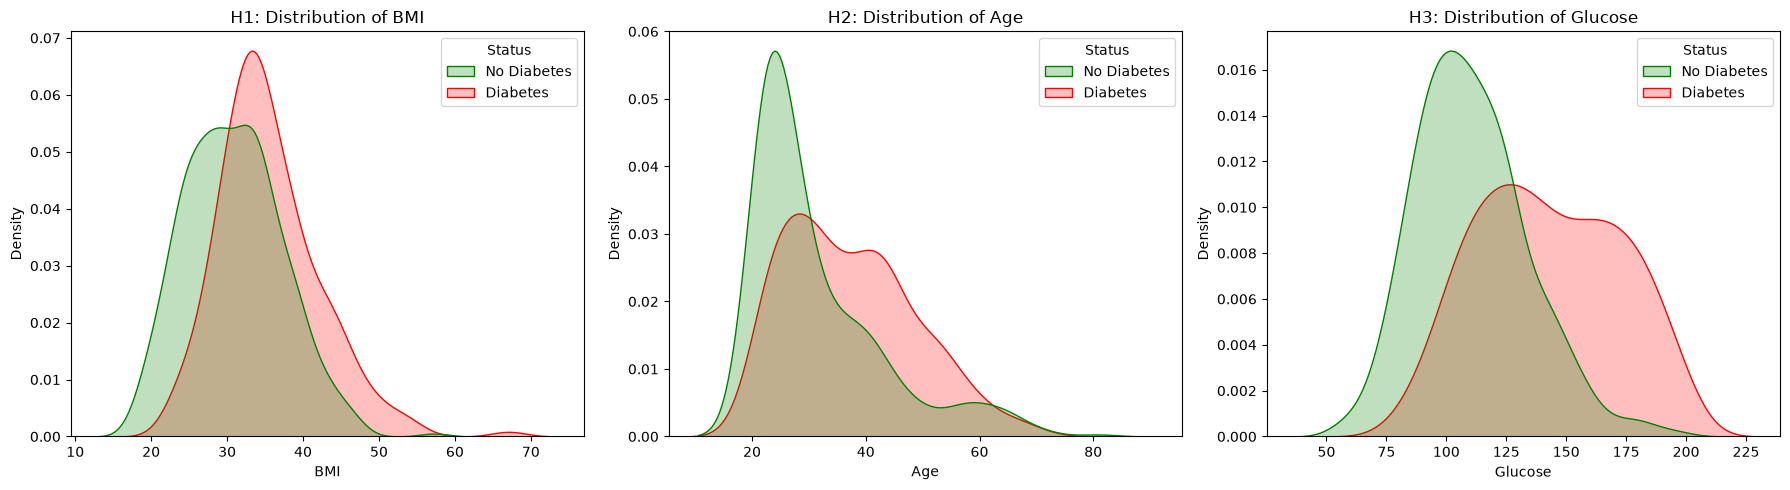

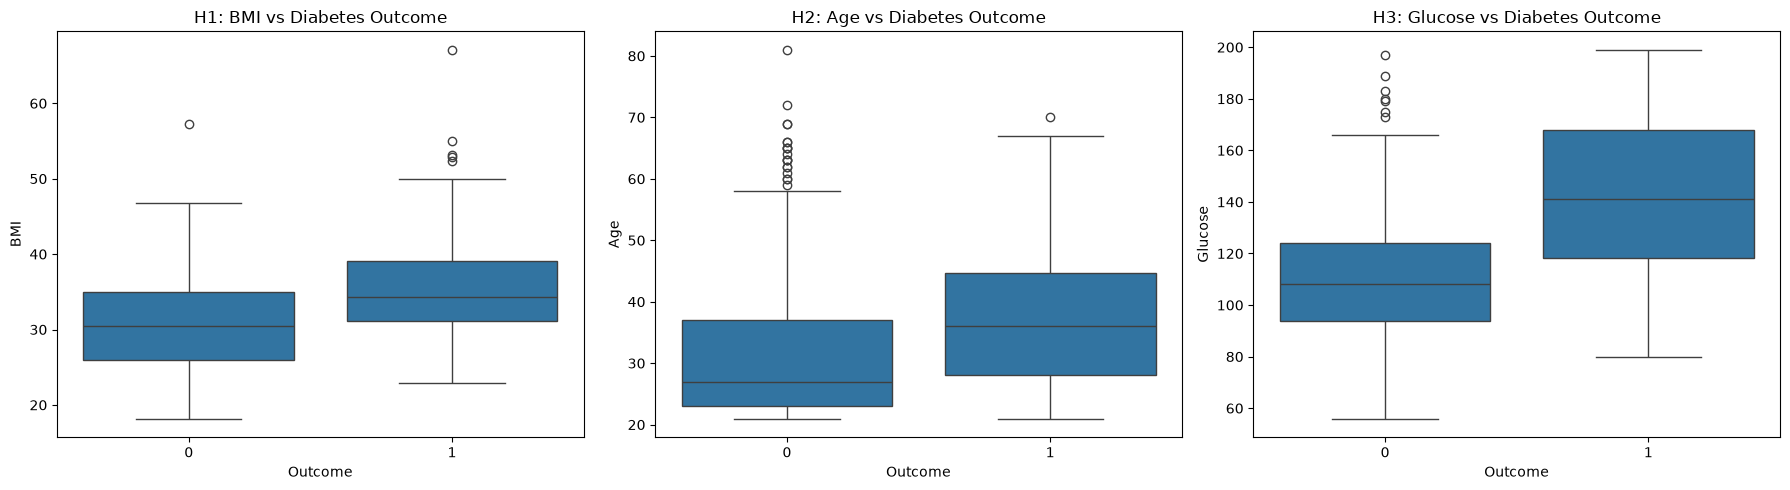

Adjusted significance level (alpha): 0.0167

--- Hypothesis for BMI ---
Mann-Whitney U p-value: 1.66e-15
Verdict: SUPPORTED (Statistically significant difference)
-----------------------------------
--- Hypothesis for Age ---
Mann-Whitney U p-value: 5.45e-14
Verdict: SUPPORTED (Statistically significant difference)
-----------------------------------
--- Hypothesis for Glucose ---
Mann-Whitney U p-value: 2.31e-34
Verdict: SUPPORTED (Statistically significant difference)
-----------------------------------


In [39]:
# --- Visualizing the Hypotheses ---


# --- (KDE Plots) ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# draw "mountains" (distributions) for each feature
sns.kdeplot(data=df_train, x='BMI', hue='Outcome', fill=True, common_norm=False, ax=axes[0], palette=['green', 'red'])
axes[0].set_title('H1: Distribution of BMI')

sns.kdeplot(data=df_train, x='Age', hue='Outcome', fill=True, common_norm=False, ax=axes[1], palette=['green', 'red'])
axes[1].set_title('H2: Distribution of Age')

sns.kdeplot(data=df_train, x='Glucose', hue='Outcome', fill=True, common_norm=False, ax=axes[2], palette=['green', 'red'])
axes[2].set_title('H3: Distribution of Glucose')

# changing the labels for clarity
for ax in axes:
    leg = ax.get_legend()
    leg.set_title("Status")
    new_labels = ['No Diabetes', 'Diabetes']
    for t, l in zip(leg.texts, new_labels): t.set_text(l)

plt.tight_layout()
plt.show()

# //////////////////////////////////////////////////////////////////////////////////////////////////////////////////////

# --- (Boxplots) ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# BMI vs Diabetes Outcome    
sns.boxplot(data=df_train, x='Outcome', y='BMI', ax=axes[0])
axes[0].set_title('H1: BMI vs Diabetes Outcome')

# Age vs Diabetes Outcome
sns.boxplot(data=df_train, x='Outcome', y='Age', ax=axes[1])
axes[1].set_title('H2: Age vs Diabetes Outcome')

# Glucose vs Diabetes Outcome
sns.boxplot(data=df_train, x='Outcome', y='Glucose', ax=axes[2])
axes[2].set_title('H3: Glucose vs Diabetes Outcome')

plt.tight_layout()
plt.show()


# //////////////////////////////////////////////////////////////////////////////////////////////////////////////////////


# --- Statistical Testing ---
alpha = 0.05 / 3  # Bonferroni correction for 3 tests
print(f"Adjusted significance level (alpha): {alpha:.4f}\n")

features_to_test = ['BMI', 'Age', 'Glucose']

for feature in features_to_test:
    # Separate the groups
    group_0 = df_train[df_train['Outcome'] == 0][feature] # No diabetes
    group_1 = df_train[df_train['Outcome'] == 1][feature] # Diabetes
    
    # Mann-Whitney U test (alternative='less' because we hypothesize group_0 < group_1)
    stat, p_value = stats.mannwhitneyu(group_0, group_1, alternative='less')
    
    print(f"--- Hypothesis for {feature} ---")
    print(f"Mann-Whitney U p-value: {p_value:.2e}")
    if p_value < alpha:
        print(f"Verdict: SUPPORTED (Statistically significant difference)")
    else:
        print(f"Verdict: CONTRADICTED / CANNOT TELL YET")
    print("-" * 35)



## Baselines, Logistic Regression, and Handling Imbalance

1. **Random Baseline**: Predicts randomly based on class distribution.
2. **Rule-Based Baseline**: Uses the strongest feature (Glucose). If a patient's glucose is above the training median of diabetic patients, we predict they have diabetes.
3. **Logistic Regression**: Standard ML model.
4. **Logistic Regression (Balanced)**: Standard model but with `class_weight="balanced"` to punish missed diabetes cases more heavily during training.
5. **Logistic Regression (Custom Threshold)**: Standard model but we lower the decision threshold from 0.5 to 0.3 to catch more positive cases.

In [40]:
# Separate features and target
X_train = df_train.drop('Outcome', axis=1)
y_train = df_train['Outcome']
#print(f"Training features: {X_train}")
#print(f"Training target: {y_train}")

# Random Baseline
dummy_model = DummyClassifier(strategy="stratified", random_state=42)
dummy_model.fit(X_train, y_train)

# Rule-based Baseline
# Find the median glucose of people WITH diabetes in the training set
glucose_cutoff = df_train[df_train['Outcome'] == 1]['Glucose'].median()
print(f"Rule-Based Baseline Cutoff: Predict 1 if Glucose > {glucose_cutoff}")

def rule_based_predict(X):
    return (X['Glucose'] > glucose_cutoff).astype(int)


# Train Logistic Regression
logreg = LogisticRegression(random_state=42, max_iter=1000)
logreg.fit(X_train, y_train)

# Handle Class Imbalance
# Option A: class_weight="balanced"  -   makes the model more afraid of missing a diabetic patient
logreg_balanced = LogisticRegression(class_weight="balanced", random_state=42, max_iter=1000)
logreg_balanced.fit(X_train, y_train)

# Option B: Lower threshold to 0.3
custom_threshold = 0.3 

def predict_with_threshold(model, X, threshold):
    # Get probabilities for Class 1 (Diabetes)
    probabilities = model.predict_proba(X)[:, 1]
    # If the model is at least 30% confident, ALARM!!!! diagnosis 1!!!
    return (probabilities >= threshold).astype(int)

Rule-Based Baseline Cutoff: Predict 1 if Glucose > 141.0


## Prepare the Test Set and Evaluate Models

Apply the **exact same cleaning steps** to the test set, using the `train_medians` we calculated earlier.

We must not calculate new medians from the test set.

Then, we evaluate all models side-by-side. Our primary metric is **Recall**, but we will track F1 and Accuracy to see the trade-offs.

In [41]:
# Prepare the test set using training medians
df_test[columns_with_hidden_zeros] = df_test[columns_with_hidden_zeros].replace(0, np.nan)
df_test[columns_with_hidden_zeros] = df_test[columns_with_hidden_zeros].fillna(train_medians)

# Separate the symptoms (X_test) from the actual diagnoses (y_test) for the test set.
X_test = df_test.drop('Outcome', axis=1)
y_test = df_test['Outcome']

# Evaluation Helper Function
def evaluate_model(y_true, y_pred):
    return {
        "Recall": recall_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred),
        "Accuracy": accuracy_score(y_true, y_pred)
    }

# Collect predictions
models_dict = {
    "Random Baseline": (dummy_model.predict(X_train), dummy_model.predict(X_test)),
    "Rule-Based (Glucose)": (rule_based_predict(X_train), rule_based_predict(X_test)),
    "LogReg (Standard)": (logreg.predict(X_train), logreg.predict(X_test)),
    "LogReg (Balanced)": (logreg_balanced.predict(X_train), logreg_balanced.predict(X_test)),
    "LogReg (Threshold 0.3)": (
        predict_with_threshold(logreg, X_train, custom_threshold), 
        predict_with_threshold(logreg, X_test, custom_threshold)
    )
}

# Calculate metrics and build table
results = []
for model_name, (pred_train, pred_test) in models_dict.items():
    train_metrics = evaluate_model(y_train, pred_train)
    test_metrics = evaluate_model(y_test, pred_test)
    
    results.append({
        "Model": model_name,
        "Train Recall": train_metrics["Recall"],
        "Test Recall": test_metrics["Recall"],
        "Train F1": train_metrics["F1"],
        "Test F1": test_metrics["F1"],
        "Train Accuracy": train_metrics["Accuracy"],
        "Test Accuracy": test_metrics["Accuracy"],
        "Precision": test_metrics["Precision"]
    })

results_df = pd.DataFrame(results).round(3)
display(results_df)

,Model,Train Recall,Test Recall,Train F1,Test F1,Train Accuracy,Test Accuracy,Precision
0,Random Baseline,0.341,0.370,0.343,0.392,0.544,0.597,0.417
1,Rule-Based (Glucose),0.495,0.444,0.586,0.516,0.756,0.708,0.615
2,LogReg (Standard),0.589,0.500,0.665,0.540,0.793,0.701,0.587
3,LogReg (Balanced),0.710,0.704,0.676,0.650,0.762,0.734,0.603
4,LogReg (Threshold 0.3),0.790,0.796,0.686,0.677,0.748,0.734,0.589


## Final Evaluation and Confusion Matrix

As seen in the table above, the standard Logistic Regression fails to catch a large portion of diabetes cases (low recall) because the classes are imbalanced. 

By applying `class_weight="balanced"` or lowering the threshold to `0.3`, we drastically increase our **Test Recall**. They both easily beat our Random and Rule-based baselines in finding true diabetes cases.

Let's look at the Confusion Matrix for the **Logistic Regression (Balanced)** to see exactly where it makes mistakes.

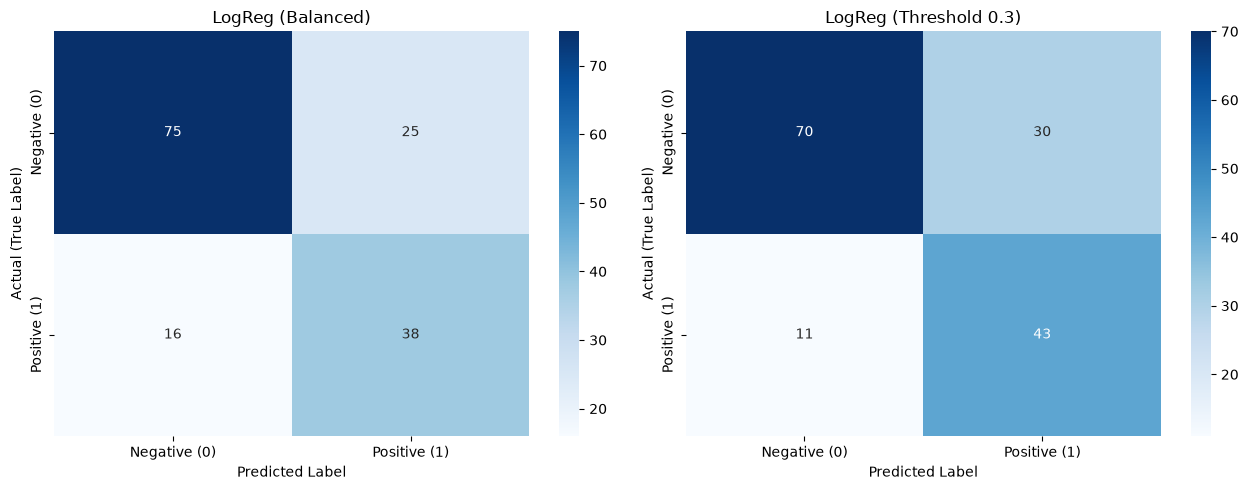

In [42]:
# Get predictions from our balanced model on the test set

# Confusion Matrix Plot
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Confusion Matrix 1: Balanced Model
best_preds_balanced = logreg_balanced.predict(X_test)
cm_balanced = confusion_matrix(y_test, best_preds_balanced)

sns.heatmap(
    cm_balanced,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Negative (0)', 'Positive (1)'],
    yticklabels=['Negative (0)', 'Positive (1)'],
    ax=axes[0]
)
axes[0].set_ylabel('Actual (True Label)')
axes[0].set_xlabel('Predicted Label')
axes[0].set_title('LogReg (Balanced)')

# Confusion Matrix 2: Threshold 0.3
best_preds_threshold = predict_with_threshold(logreg, X_test, 0.3)
cm_threshold = confusion_matrix(y_test, best_preds_threshold)                                                                                                        

sns.heatmap(
    cm_threshold,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Negative (0)', 'Positive (1)'],
    yticklabels=['Negative (0)', 'Positive (1)'],
    ax=axes[1]
)
axes[1].set_ylabel('Actual (True Label)')
axes[1].set_xlabel('Predicted Label')
axes[1].set_title('LogReg (Threshold 0.3)')

plt.tight_layout()
plt.show()

## Final Evaluation and Conclusion

As seen in our results table, the **Standard Logistic Regression** fails to catch a large portion of diabetes cases (Test Recall = 0.500). Because the dataset is imbalanced, the model heavily favors predicting the majority class (Healthy), completely missing 50% of the sick patients. 

To fix this, we applied two techniques and plotted their Confusion Matrices side-by-side to observe the exact trade-offs:
1. **LogReg (Balanced):** Caught 38 actual diabetes cases, but completely missed 16 cases (False Negatives).
2. **LogReg (Threshold 0.3):** Caught 43 diabetes cases, reducing the highly dangerous False Negatives down to only 11. 

**Conclusion:**
In a medical screening context, a False Negative (missing a diabetes diagnosis) is vastly more dangerous than a False Positive (a false alarm). Therefore, **LogReg with a 0.3 Threshold is our clear winner**. By intentionally lowering the decision threshold, we achieved a peak Test Recall of **0.796**, successfully catching about 80% of all real cases. While this slightly increased the number of false alarms (from 25 to 30 Healthy people flagged as sick), a follow-up blood test will easily resolve these false alarms, making it a highly acceptable trade-off to save lives.